# FinPay | Data Understanding

## Overview

This notebook explores the **FinPay payments dataset** through checks of missing values, column types, distinct counts, category distributions, and selected payment-operation metrics. Its purpose is to help readers understand each table's contents and how the tables support further analysis—not to serve as a complete data-quality certification.

**Scope:** Six dimension tables and seven transaction/operation fact tables are examined below. The `fact_fx_rate` table is loaded as part of the preparation workflow but does not have a separate exploratory-analysis section in this notebook.

**How to read it:** Start with data loading, then explore reference and entity tables (`dim_*`), followed by transactional and financial event tables (`fact_*`). The original findings and code outputs remain in place under their corresponding headings.

<a id="contents"></a>
## Table of contents

Click any link to jump directly to that section. The headings also appear in the notebook outline in compatible Jupyter interfaces.

- [1. Environment and data loading](#setup)
- **2. Dimension tables**
  - [2.1 `dim_currency` — Currencies](#dim-currency)
  - [2.2 `dim_market` — Markets](#dim-market)
  - [2.3 `dim_gateway` — Payment gateways](#dim-gateway)
  - [2.4 `dim_merchant` — Merchants](#dim-merchant)
  - [2.5 `dim_customer` — Customers](#dim-customer)
  - [2.6 `dim_date` — Calendar](#dim-date)
- **3. Fact tables**
  - [3.1 `fact_payment_intent` — Payment intents](#fact-payment-intent)
  - [3.2 `fact_payment_attempt` — Payment attempts](#fact-payment-attempt)
  - [3.3 `fact_fee` — Fees and processor costs](#fact-fee)
  - [3.4 `fact_refund` — Refunds](#fact-refund)
  - [3.5 `fact_dispute` — Disputes](#fact-dispute)
  - [3.6 `fact_settlement` — Merchant payouts](#fact-settlement)
  - [3.7 `fact_merchant_ledger` — Merchant ledger entries](#fact-merchant-ledger)
- [4. Saving processed data](#saving-data)

### Reading conventions

- **Missingness:** `null_count()` reveals missing values; the existing notes discuss possible business explanations for selected nulls.
- **Schema and uniqueness:** `.schema`, `.n_unique()`, and `.value_counts()` describe types and observed categories; a distinct-value count alone does not validate key integrity.
- **Financial units:** Preparation logic derives major-unit and USD amounts for several fact tables using the currency reference and historical FX data. Use the column suffixes to distinguish original and converted amounts.
- **Charts:** Percentage plots describe the distribution in the table or subgroup being analyzed. Always check their denominators before comparing across sections.

**Note:** Descriptions added to this notebook explain what the existing cells inspect; they do not replace or independently validate the original calculations.

<a id="setup"></a>
## 1. Environment and data loading

The first cells import Polars and visualization libraries, load preparation/chart helpers, and materialize prepared tables for inspection. `load_data()` is defined in `src.preprocessing`; the existing optional save call is commented out.

In [1]:
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn as sns
import matplotlib.pyplot as plt

from src.preprocessing import load_data, save_processed_data
from src.visualization import plot_total_attempts_by_payment_method_analysis

#### Load tables into memory

The following cell calls `load_data()` and collects each table into a Polars DataFrame. All subsequent sections use these named DataFrames; the original loading code is kept unchanged.

In [2]:
data = load_data()

# collect data
dim_currency = data["dim_currency"].collect()
dim_market = data["dim_market"].collect()
dim_gateway = data["dim_gateway"].collect()
dim_merchant = data["dim_merchant"].collect()
dim_customer = data["dim_customer"].collect()
dim_date = data["dim_date"].collect()
fact_payment_intent = data["fact_payment_intent"].collect()
fact_payment_attempt = data["fact_payment_attempt"].collect()
fact_fee = data["fact_fee"].collect()
fact_refund = data["fact_refund"].collect()
fact_dispute = data["fact_dispute"].collect()
fact_settlement = data["fact_settlement"].collect()
fact_merchant_ledger = data["fact_merchant_ledger"].collect()
fact_fx_rate = data["fact_fx_rate"].collect()

Data loaded


## 2. Dimension tables

Dimension tables describe currencies, markets, gateways, merchants, customers, and calendar attributes. These provide context for interpreting events in the fact tables.

<a id="dim-currency"></a>
### 2.1 `dim_currency` — Currency reference

This table identifies the supported currencies and their minor-unit conventions. The next cells inspect missing values, data types, and the number of distinct currency codes.

In [3]:
# dim currency missing values
dim_currency.null_count()

currency_code,minor_units,currency_name
u32,u32,u32
0,0,0


In [4]:
# dim currency dtypes
dim_currency.schema

Schema([('currency_code', String),
        ('minor_units', Int64),
        ('currency_name', String)])

In [5]:
# Number of unique currencies
dim_currency.get_column("currency_code").unique().count()

10

The Japanese Yen has **minor_units=0** except all other currencies that have **minor_units=2**.

<a id="dim-market"></a>
### 2.2 `dim_market` — Market reference

This section checks the reference list of markets, including missing values, schema, and the count of distinct country codes.

In [6]:
dim_market.null_count()

country_code,market_name,currency_code,timezone
u32,u32,u32,u32
0,0,0,0


In [7]:
dim_market.schema

Schema([('country_code', String),
        ('market_name', String),
        ('currency_code', String),
        ('timezone', String)])

In [8]:
# Number of unique market countries that our company has data for
dim_market.select(
    pl.col('country_code').n_unique().alias('unique_countries')
)

unique_countries
u32
12


<a id="dim-gateway"></a>
### 2.3 `dim_gateway` — Payment gateways

These cells check gateway data completeness and types, count distinct gateways, and examine whether they are enabled.

In [9]:
dim_gateway.null_count()

gateway_id,gateway_name,home_region,is_enabled
u32,u32,u32,u32
0,0,0,0


In [10]:
dim_gateway.schema

Schema([('gateway_id', Int64),
        ('gateway_name', String),
        ('home_region', String),
        ('is_enabled', Int64)])

In [11]:
# Number of unique gateways our company offers to the merchants
dim_gateway.select(
    pl.col("gateway_id").n_unique().alias("unique_gateways")
)

unique_gateways
u32
5


In [12]:
dim_gateway['is_enabled'].value_counts() # all gateways are enabled

is_enabled,count
i64,u32
1,5


<a id="dim-merchant"></a>
### 2.4 `dim_merchant` — Merchant profiles

The merchant table provides attributes such as country, industry, settlement currency, pricing tier, payout frequency, and account status. The section begins with completeness and type checks.

In [13]:
dim_merchant.null_count()

merchant_id,merchant_name,country_code,industry,onboarded_at,settlement_currency,pricing_tier,payout_frequency,account_status
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0


In [14]:
dim_merchant.schema

Schema([('merchant_id', Int64),
        ('merchant_name', String),
        ('country_code', Categorical),
        ('industry', Categorical),
        ('onboarded_at', Datetime(time_unit='us', time_zone=None)),
        ('settlement_currency', Categorical),
        ('pricing_tier', Categorical),
        ('payout_frequency', Categorical),
        ('account_status', Categorical)])

#### Merchant population and available attributes

The following cells count merchants and distinct attribute categories, then inspect the observed industry, pricing, payout, and account-status values.

In [15]:
# dim_merchant attributes
print(f"Number of unique merchants: {dim_merchant['merchant_id'].n_unique()}")
print(f"Number of available coutries: {dim_merchant['country_code'].n_unique()}")
print(f"Number of available industries: {dim_merchant['industry'].n_unique()}")
print(f"Number of available settlement currencies: {dim_merchant['settlement_currency'].n_unique()}")
print(f"Number of available pricing tiers: {dim_merchant['pricing_tier'].n_unique()}")
print(f"Number of possible payout frequencies: {dim_merchant['payout_frequency'].n_unique()}")
print(f"Number of available account statuses: {dim_merchant['account_status'].n_unique()}")

Number of unique merchants: 2000
Number of available coutries: 12
Number of available industries: 6
Number of available settlement currencies: 10
Number of available pricing tiers: 3
Number of possible payout frequencies: 2
Number of available account statuses: 1


In [16]:
# deeper dive into the each column available category
print(f"Different active industries: {dim_merchant['industry'].unique().to_list()}")
print(f"Different active pricing tiers: {dim_merchant['pricing_tier'].unique().to_list()}")
print(f"Different active payout frequencies: {dim_merchant['payout_frequency'].unique().to_list()}")
print(f"Percentage of active merchants: {dim_merchant['account_status'].value_counts(normalize=True)['proportion'][0] * 100:.2f}%")

Different active industries: ['electronics', 'services', 'retail', 'travel', 'subscriptions', 'food']
Different active pricing tiers: ['starter', 'growth', 'enterprise']
Different active payout frequencies: ['monthly', 'weekly']
Percentage of active merchants: 100.00%


#### Merchant geography and industry mix

The results below show merchants' country-level distribution and the relative share of industries, including a chart of industry composition.

In [17]:
# Percentage of merchants by country
dim_merchant['country_code'].value_counts(normalize=True).select(
    pl.col('country_code'),
    (pl.col('proportion') * 100).alias("percentage"),
).sort(by="percentage", descending=True).show(12)

country_code,percentage
cat,f64
"""US""",21.65
"""GB""",11.3
"""DE""",9.85
"""CA""",9.05
"""FR""",8.4
"""JP""",8.15
"""CN""",6.75
"""AU""",6.05
"""MX""",5.8


In [18]:
dim_merchant['industry'].value_counts().select(
    pl.col('industry'),
    (pl.col('count') / dim_merchant.shape[0] * 100).alias('merchant_share')
).sort('merchant_share', descending=True).show(12)

industry,merchant_share
cat,f64
"""retail""",31.85
"""services""",18.1
"""electronics""",15.9
"""food""",14.2
"""subscriptions""",12.2
"""travel""",7.75


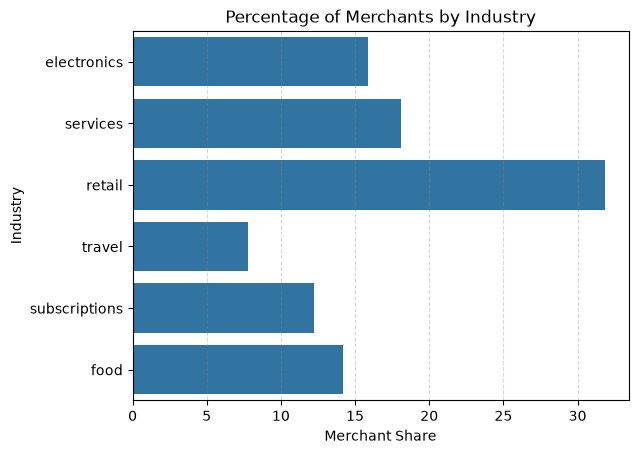

In [19]:
sns.countplot(
    data=dim_merchant.to_pandas(),
    y="industry",
    stat="percent",
)

plt.title("Percentage of Merchants by Industry")
plt.ylabel("Industry")
plt.xlabel("Merchant Share")
plt.grid(True, axis="x", color="grey", linestyle="--", alpha=0.3)

<a id="dim-customer"></a>
### 2.5 `dim_customer` — Customer profiles

The customer section checks completeness and field types before reviewing how customers were acquired.

In [20]:
# dim customer missing values
dim_customer.null_count()

customer_id,signed_up_at,country_code,acquisition_channel,is_verified
u32,u32,u32,u32,u32
0,0,0,0,0


In [21]:
dim_customer.schema

Schema([('customer_id', Int64),
        ('signed_up_at', Datetime(time_unit='us', time_zone=None)),
        ('country_code', Categorical),
        ('acquisition_channel', Categorical),
        ('is_verified', Categorical)])

#### Customer acquisition channels

These cells count the distinct acquisition channels and compare their representation in the customer table, both numerically and visually.

In [22]:
# Number of unique customer acquisition channels
dim_customer['acquisition_channel'].n_unique()

5

In [23]:
dim_customer['acquisition_channel'].value_counts().select(
    pl.col('acquisition_channel'),
    (pl.col('count') / dim_customer.shape[0] * 100).alias('percentage_of_customers')
).sort('percentage_of_customers', descending=True).show(5)

acquisition_channel,percentage_of_customers
cat,f64
"""organic""",35.976
"""paid_search""",22.885
"""referral""",18.152
"""social""",15.021
"""partner""",7.966


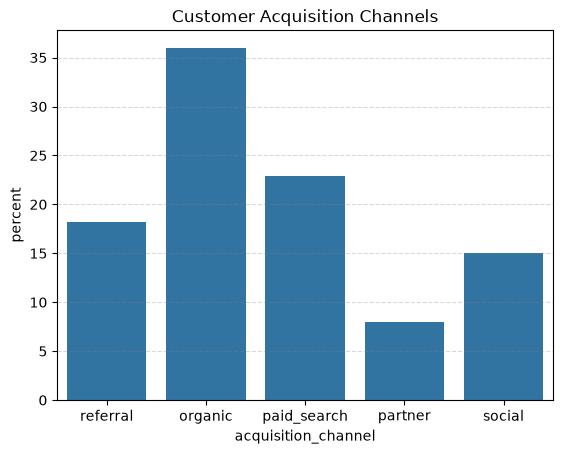

In [24]:
sns.countplot(
	data=dim_customer.to_pandas(),
    x="acquisition_channel",
    stat="percent",
)
plt.title("Customer Acquisition Channels")
plt.grid(True, axis='y', linestyle='--', alpha=0.3, color='grey')

<a id="dim-date"></a>
### 2.6 `dim_date` — Calendar dimension

This short section verifies missing values and schema in the prepared calendar dimension, which supports time-based analysis.

In [25]:
dim_date.null_count()

date_key,date_utc,year,month,day_of_month,week,day_of_week,is_business_day,month_start,month_end,is_weekend
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


In [26]:
dim_date.schema

Schema([('date_key', Int64),
        ('date_utc', Datetime(time_unit='us', time_zone=None)),
        ('year', Int32),
        ('month', Int8),
        ('day_of_month', Int8),
        ('week', Int8),
        ('day_of_week', Int8),
        ('is_business_day', Boolean),
        ('month_start', Datetime(time_unit='us', time_zone=None)),
        ('month_end', Datetime(time_unit='us', time_zone=None)),
        ('is_weekend', Boolean)])

## 3. Fact tables

Fact tables capture payment intents, attempts, fees, refunds, disputes, settlements, and merchant-ledger events. Each subsection names the **specific table being analyzed**, even where a cell references another table for comparison.

<a id="fact-payment-intent"></a>
### 3.1 `fact_payment_intent` — Payment intents

A payment intent represents a checkout-level payment request. This section examines missingness, customer participation, checkout channels, final outcomes, and schema. The next cell begins with null counts.

In [27]:
fact_payment_intent.null_count()

intent_id,merchant_id,customer_id,created_at,buyer_country,checkout_channel,presentment_currency,final_outcome,closed_at,captured_at,amount_major,captured_settlement_major,payment_resolution_time,time_to_capture,amount_major_usd,captured_settlement_major_usd
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,437109,0,0,0,0,0,1827,184243,0,184243,1827,184243,0,184243


- Null values of the **customer_id** shows the host customers that didn't signup to the services.
- Null values of the **captured_at** are because of the **final_outcome=pending**.
- Null values of the **captured_at** and **capture_settlement_minor** are because of the **final_outcome in ['pending', 'failed', 'abandoned']**.

#### Missing timestamps and payment outcomes

The original note above provides the author's interpretation of selected missing fields. The next queries specifically inspect the outcome categories associated with missing `closed_at` and `captured_at` values.

In [28]:
# final outcome of the payment intents with null closed_at
fact_payment_intent.filter(
    pl.col("closed_at").is_null()
).select(
    pl.col('final_outcome').unique(),
    pl.len()
)

final_outcome,len
cat,u32
"""pending""",1827


In [29]:
# Null values of the captured_at column
fact_payment_intent.filter(
    pl.col('captured_at').is_null()
).select(
    pl.col('final_outcome').unique(maintain_order=True)
)

final_outcome
cat
"""failed"""
"""abandoned"""
"""pending"""


#### Customer participation

These queries count distinct customer IDs associated with payment intents and calculate the difference from the notebook's 100,000-customer reference population. This is an exploratory participation count, not a count of all payment attempts.

In [30]:
# Number of customers that have made a payment
fact_payment_intent.select(
    pl.col('customer_id').n_unique()
)

customer_id
u32
94361


In [31]:
# Number of customers that have not showed up in fact_payment_intent
fact_payment_intent.select(
    (100_000 - pl.col('customer_id').n_unique())
)

literal
u32
5639


#### Checkout channels and final outcomes

The next cells visualize the proportion of intents by checkout channel, summarize final-outcome categories, and chart their distribution.

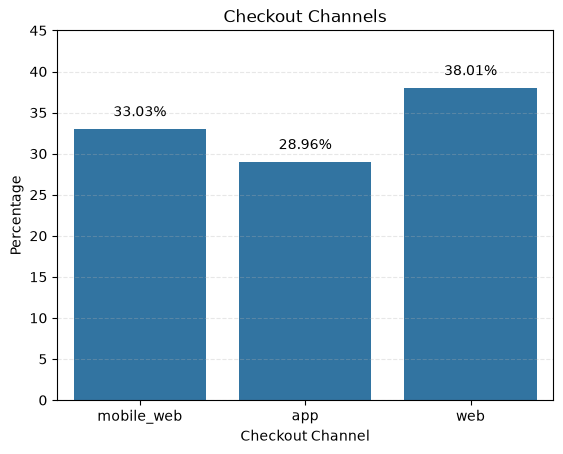

In [32]:
mobile_web_pcn = fact_payment_intent.filter(
    pl.col('checkout_channel') == "mobile_web"
).select(
    pl.col('intent_id').count() / fact_payment_intent.shape[0] * 100
)['intent_id'].to_list()[0]

web_pcn = fact_payment_intent.filter(
    pl.col('checkout_channel') == "web"
).select(
    pl.col('intent_id').count() / fact_payment_intent.shape[0] * 100
)['intent_id'].to_list()[0]

app_pcn = fact_payment_intent.filter(
    pl.col('checkout_channel') == "app"
).select(
    pl.col('intent_id').count() / fact_payment_intent.shape[0] * 100
)['intent_id'].to_list()[0]

sns.countplot(
    data=fact_payment_intent.to_pandas(),
    x="checkout_channel",
    stat="percent"
)

plt.text(0, 35, f"{mobile_web_pcn:.2f}%", ha="center", va="center")
plt.text(1, 31, f"{app_pcn:.2f}%", ha="center", va="center")
plt.text(2, 40, f"{web_pcn:.2f}%", ha="center", va="center")

plt.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.ylim(0, 45)

plt.title("Checkout Channels")
plt.ylabel("Percentage")
plt.xlabel("Checkout Channel")
plt.show()

In [33]:
fact_payment_intent.select(
    pl.col('final_outcome').unique(maintain_order=True),
    (pl.col('final_outcome').unique_counts() / fact_payment_intent.shape[0] * 100).alias("count")
)

final_outcome,count
cat,f64
"""succeeded""",88.626975
"""failed""",8.082778
"""abandoned""",3.177469
"""pending""",0.112778


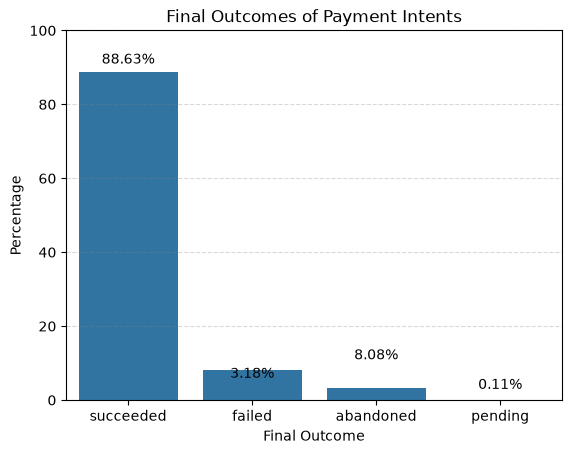

In [34]:
sns.countplot(
	data=fact_payment_intent.to_pandas(),
    x="final_outcome",
	stat="percent"
)

succeeded_pcn = fact_payment_intent.filter(
    pl.col('final_outcome') == "succeeded"
).select(
    pl.col('final_outcome').count() / fact_payment_intent.shape[0] * 100
)['final_outcome'].to_list()[0]

failed_pcn = fact_payment_intent.filter(
    pl.col('final_outcome') == "failed"
).select(
    pl.col('final_outcome').count() / fact_payment_intent.shape[0] * 100
)['final_outcome'].to_list()[0]

pending_pcn = fact_payment_intent.filter(
    pl.col('final_outcome') == "pending"
).select(
    pl.col('final_outcome').count() / fact_payment_intent.shape[0] * 100
)['final_outcome'].to_list()[0]

abandoned_pcn = fact_payment_intent.filter(
    pl.col('final_outcome') == "abandoned"
).select(
    pl.col('final_outcome').count() / fact_payment_intent.shape[0] * 100
)['final_outcome'].to_list()[0]

plt.text(0, 92, f"{succeeded_pcn:.2f}%", ha="center", va="center")
plt.text(1, 7, f"{abandoned_pcn:.2f}%", ha="center", va="center")
plt.text(2, 12, f"{failed_pcn:.2f}%", ha="center", va="center")
plt.text(3, 4, f"{pending_pcn:.2f}%", ha="center", va="center")

plt.ylim(0, 100)
plt.grid(True, axis="y", linestyle="--", color="grey", alpha=0.3)

plt.title("Final Outcomes of Payment Intents")
plt.xlabel("Final Outcome")
plt.ylabel("Percentage")
plt.show()

#### Payment-intent schema

The following schema output documents the data types available for subsequent analysis.

In [35]:
fact_payment_intent.schema

Schema([('intent_id', Int64),
        ('merchant_id', Int64),
        ('customer_id', Int64),
        ('created_at', Datetime(time_unit='us', time_zone=None)),
        ('buyer_country', Categorical),
        ('checkout_channel', Categorical),
        ('presentment_currency', Categorical),
        ('final_outcome', Categorical),
        ('closed_at', Datetime(time_unit='us', time_zone=None)),
        ('captured_at', Datetime(time_unit='us', time_zone=None)),
        ('amount_major', Float64),
        ('captured_settlement_major', Float64),
        ('payment_resolution_time', Int64),
        ('time_to_capture', Int64),
        ('amount_major_usd', Float64),
        ('captured_settlement_major_usd', Float64)])

<a id="fact-payment-attempt"></a>
### 3.2 `fact_payment_attempt` — Payment attempts

A payment intent may lead to one or more payment attempts. Here the analysis explores missing fields, attempt numbers, payment methods, gateway usage, outcomes, failure reasons, and processing latency.

In [36]:
fact_payment_attempt.null_count()

attempt_id,intent_id,gateway_id,attempt_number,started_at,finished_at,payment_method,outcome,failure_reason,latency_ms
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,1827,0,0,1437584,1827


- **finished_at** includes 1827 null values and they are because the outcome of the payment is pending and the payment has not been captured yet.
- **failure_reason** column has 1,437,584 null values and they are because the outcome is succeeded and there is no failure reason.
- **latency_ms** has 1,827 null values and they are because the outcome in these rows is pending.

In [37]:
fact_payment_attempt.schema

Schema([('attempt_id', Int64),
        ('intent_id', Int64),
        ('gateway_id', Int64),
        ('attempt_number', Categorical),
        ('started_at', Datetime(time_unit='us', time_zone=None)),
        ('finished_at', Datetime(time_unit='us', time_zone=None)),
        ('payment_method', Categorical),
        ('outcome', Categorical),
        ('failure_reason', Categorical),
        ('latency_ms', Int64)])

#### Attempt counts and intent coverage

The next cells compare the number of attempt records with intent records, inspect first attempts, and count distinct intent IDs represented in the attempts table.

**Interpretation note:** The difference between the total number of attempts and the total number of intents is **not** itself a direct count of failed attempts; use the `outcome` field for failure-specific counts. The original expression is intentionally unchanged.

In [38]:
# Number of the unsuccessful attempts
fact_payment_attempt['attempt_id'].count() - fact_payment_intent['intent_id'].count()

45396

In [39]:
fact_payment_attempt.filter(
    pl.col('attempt_number') == '1'
).select(
    pl.col('outcome').unique(maintain_order=True),
    pl.col('outcome').unique_counts().alias("count")
).show()

outcome,count
cat,u32
"""succeeded""",1381013
"""failed""",185685
"""pending""",1827


In [40]:
# Number of unique intent values
fact_payment_attempt['intent_id'].n_unique()

1568525

**Abandoned** payment intents are not represented in the fact_payment_attempt table.

#### Gateway usage and retry patterns

These cells show the distribution of attempts by gateway and by attempt number, including a visual breakdown of first, second, and third attempts.

In [41]:
fact_payment_attempt['gateway_id'].value_counts()

gateway_id,count
i64,u32
3,333633
2,330042
5,335745
4,333069
1,332907


In [42]:
fact_payment_attempt.select(
    pl.col('attempt_number').unique(maintain_order=True),
    pl.col('attempt_number').unique_counts().alias("count") / fact_payment_attempt.shape[0] * 100
)

attempt_number,count
cat,f64
"""1""",94.183305
"""2""",5.359446
"""3""",0.457249


Text(0.5, 0, 'Attempt Number')

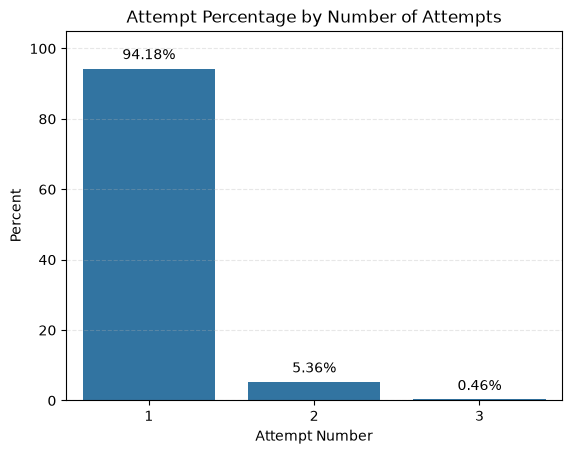

In [43]:
one_pcn = fact_payment_attempt.filter(
    pl.col('attempt_number') == '1'
).select(
    pl.col('attempt_id').count() / fact_payment_attempt.shape[0] * 100
)['attempt_id'].to_list()[0]

two_pcn = fact_payment_attempt.filter(
    pl.col('attempt_number') == '2'
).select(
    pl.col('attempt_id').count() / fact_payment_attempt.shape[0] * 100
)['attempt_id'].to_list()[0]

three_pcn = fact_payment_attempt.filter(
    pl.col('attempt_number') == '3'
).select(
    pl.col('attempt_id').count() / fact_payment_attempt.shape[0] * 100
)['attempt_id'].to_list()[0]

sns.countplot(
    data=fact_payment_attempt.to_pandas(),
    x="attempt_number",
	stat="percent"
)

plt.text(0, 98, f"{one_pcn:.2f}%", ha="center", va="center")
plt.text(1, 9, f"{two_pcn:.2f}%", ha="center", va="center")
plt.text(2, 4, f"{three_pcn:.2f}%", ha="center", va="center")

plt.ylim(0, 105)
plt.grid(True, axis="y", linestyle="--", alpha=0.3)

plt.title("Attempt Percentage by Number of Attempts")
plt.ylabel("Percent")
plt.xlabel("Attempt Number")

#### Payment methods and attempt outcomes

The next results break down attempts by payment method and outcome. The cross-tabulation and visualization help distinguish overall method share from outcome percentages within each method.

In [44]:
fact_payment_attempt.group_by("payment_method").agg(
    (pl.col('payment_method').count() / fact_payment_attempt.shape[0] * 100).alias("precentage")
)

payment_method,precentage
cat,f64
"""bank_debit""",18.020038
"""card""",30.281266
"""wallet""",51.698695


In [45]:
fact_payment_attempt.group_by("outcome").agg(
    (pl.col('outcome').count() / fact_payment_attempt.shape[0] * 100).alias("percentage")
)

outcome,percentage
cat,f64
"""succeeded""",86.211147
"""failed""",13.679149
"""pending""",0.109704


In [46]:
total_bank_debit_attempts = fact_payment_attempt.filter(
    pl.col("payment_method") == "bank_debit"
).shape[0]

total_card_attempts = fact_payment_attempt.filter(
    pl.col("payment_method") == "card"
).shape[0]

total_wallet_attempts = fact_payment_attempt.filter(
    pl.col("payment_method") == "wallet"
).shape[0]

fact_payment_attempt.pivot(
    on="outcome",
    index="payment_method",
    values="attempt_id",
    aggregate_function=(pl.len())
).with_columns(
    pl.when(
        pl.col('payment_method') == "bank_debit"
	).then(
        pl.col('succeeded', 'failed', 'pending') / total_bank_debit_attempts * 100
	).name.suffix("_bank_pcn"),
    pl.when(
		pl.col('payment_method') == "card"
	).then(
		pl.col('succeeded', 'failed', 'pending') / total_card_attempts * 100
	).name.suffix('_card_pcn'),
    pl.when(
		pl.col('payment_method') == "wallet"
	).then(
		pl.col('succeeded', 'failed', 'pending') / total_wallet_attempts * 100
	).name.suffix('_wallet_pcn')
)

payment_method,succeeded,failed,pending,succeeded_bank_pcn,failed_bank_pcn,pending_bank_pcn,succeeded_card_pcn,failed_card_pcn,pending_card_pcn,succeeded_wallet_pcn,failed_wallet_pcn,pending_wallet_pcn
cat,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""bank_debit""",245156,54605,344,81.690075,18.195298,0.114627,null,null,null,null,null,null
"""card""",425171,78596,536,null,null,null,84.30864,15.585075,0.106285,null,null,null
"""wallet""",765430,94611,947,null,null,null,null,null,null,88.901355,10.988655,0.10999


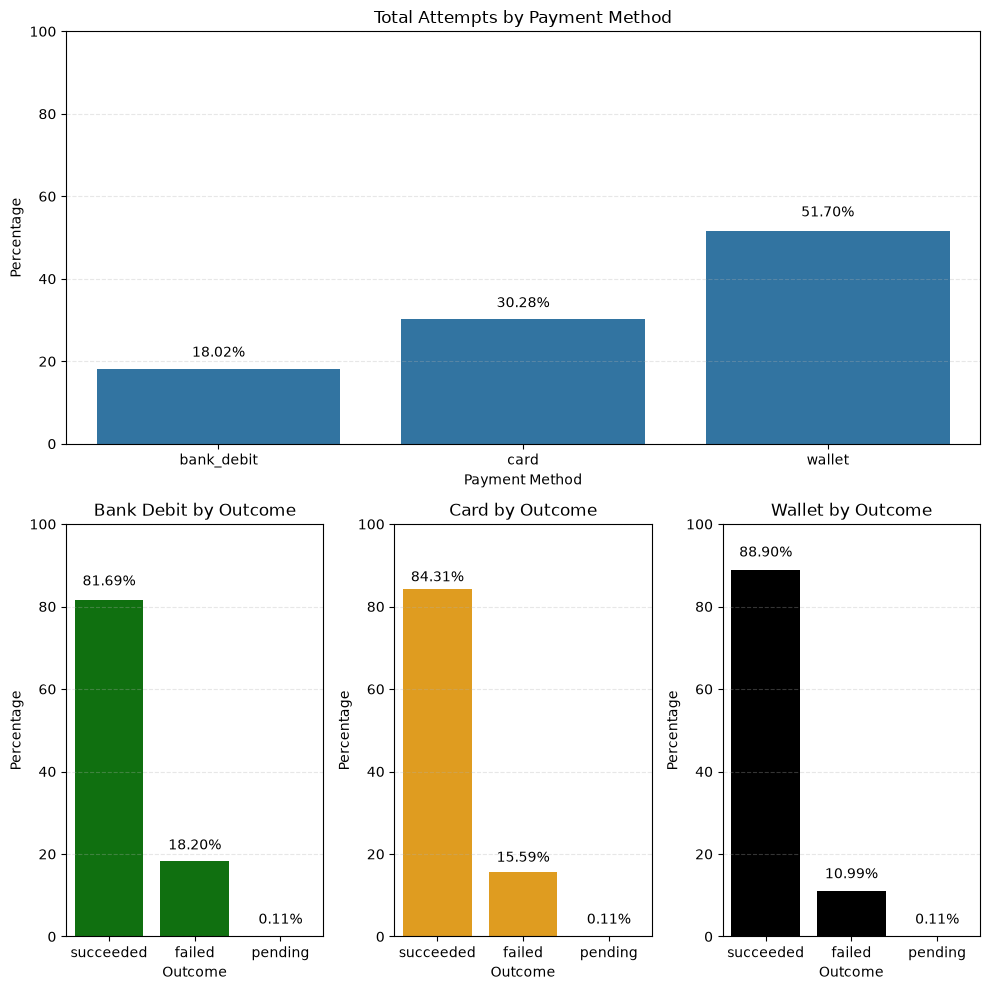

In [47]:
plot_total_attempts_by_payment_method_analysis(fact_payment_attempt)

#### Failure reasons and latency

These cells investigate failure reasons by outcome, the distribution of reasons among failed attempts, and summary statistics of `latency_ms` grouped by failure reason.

In [48]:
# failure reasons by outcome
fact_payment_attempt.pivot(
	on='outcome',
    index='failure_reason',
    values="attempt_id",
    aggregate_function=pl.len()
)

failure_reason,succeeded,failed,pending
cat,u32,u32,u32
null,1435757,0,1827
"""insufficient_funds""",0,65405,0
"""suspected_fraud""",0,24985,0
"""network_timeout""",0,41739,0
"""issuer_decline""",0,66111,0
"""authentication_failed""",0,29572,0


In [49]:
fact_payment_attempt.filter(
    pl.col('outcome') == 'failed'
).group_by('failure_reason').agg(
    pl.len() / fact_payment_attempt.filter(
        pl.col('outcome') == 'failed'
	).shape[0] * 100
)

failure_reason,len
cat,f64
"""issuer_decline""",29.019981
"""insufficient_funds""",28.710077
"""authentication_failed""",12.980879
"""suspected_fraud""",10.967377
"""network_timeout""",18.321686


In [50]:
fact_payment_attempt.group_by("failure_reason").agg(
    pl.col('latency_ms').mean().alias("mean_latency_ms"),
    pl.col('latency_ms').std().alias("std_latency_ms"),
    pl.col('latency_ms').max().alias("max_latency_ms"),
    pl.col('latency_ms').min().alias("min_latency_ms"),
)

failure_reason,mean_latency_ms,std_latency_ms,max_latency_ms,min_latency_ms
cat,f64,f64,i64,i64
null,1319.062251,640.826055,2100,140
"""insufficient_funds""",1373.385429,710.660204,2599,140
"""issuer_decline""",1368.662825,711.285484,2599,140
"""suspected_fraud""",1369.347529,707.25793,2599,140
"""authentication_failed""",1373.253246,710.135258,2599,140
"""network_timeout""",1547.981025,1550.251594,17979,140


<a id="fact-fee"></a>
### 3.3 `fact_fee` — Merchant fees and processing costs

This section profiles fee-record completeness and types, then examines coverage across intents and the number of entries by fee type. The existing explanatory notes distinguish merchant fees, processor costs, and dispute fees.

In [51]:
fact_fee.null_count()

fee_id,intent_id,dispute_id,assessed_at,fee_type,settlement_currency,amount_settlement_major,amount_settlement_major_usd
u32,u32,u32,u32,u32,u32,u32,u32
0,0,2871514,0,0,0,0,0


Null value are fees that do not disputed.

In [52]:
fact_fee.schema

Schema([('fee_id', Int64),
        ('intent_id', Int64),
        ('dispute_id', Int64),
        ('assessed_at', Datetime(time_unit='us', time_zone=None)),
        ('fee_type', Categorical),
        ('settlement_currency', Categorical),
        ('amount_settlement_major', Float64),
        ('amount_settlement_major_usd', Float64)])

#### Fee coverage and payment-outcome context

The first query counts distinct intents in `fact_fee`; the next intentionally queries **`fact_payment_intent`**, not `fact_fee`, to provide an outcome-level comparison.

In [53]:
fact_fee.select(
    pl.col('intent_id').n_unique()
)

intent_id
u32
1435757


In [54]:
fact_payment_intent.group_by("final_outcome").agg(
    pl.col("intent_id").count()
)

final_outcome,intent_id
cat,u32
"""abandoned""",51475
"""succeeded""",1435757
"""failed""",130941
"""pending""",1827


Number of unique intens in the **fact_fee** table are those intents that their **final_outcome="succeeded"**.

#### Fee categories

The code below groups fee records by `fee_type`. The author's original explanation of each fee category follows it.

In [55]:
fact_fee.group_by('fee_type').agg(
    cs.by_name('fee_id').count()
)

fee_type,fee_id
cat,u32
"""dispute_fee""",626
"""merchant_fee""",1435757
"""processor_cost""",1435757


Each intent includes a **merchant_fee** that is our business revenue and a **processor_cost** that is our business expense, some intents may have a dispute on them and if the merchant looses the dispute our business will charge them a **dispute_fee**.

<a id="fact-refund"></a>
### 3.4 `fact_refund` — Refund activity

Refunds represent requests to return funds. This section inspects missing values, refund and intent identifiers, processing status, reasons, and their distributions.

In [56]:
fact_refund.null_count()

refund_id,intent_id,requested_at,completed_at,minutes_to_refund,status,reason,currency_code,amount_major,settlement_debit_major,settlement_debit_major_usd,amount_major_usd
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,1965,1965,0,0,0,0,3187,3187,0


- Null values of the **completed_at** column are because of that the **status="pending"**.
- Null values of the **settlement_debit_minor** column are because of thet we create another column from **amount_minor** that the refunds with **status="failed"** or **status="pending"** have null values and values are just for **status="succeeded"**.

#### Refund volume, intent coverage, and status

These cells compare the number of distinct refund IDs with distinct related intent IDs, then inspect status counts and missing values among pending refunds.

In [57]:
fact_refund.select(
    cs.by_name('refund_id').n_unique().alias('n_unique_refund_ids')
)

n_unique_refund_ids
u32
45503


In [58]:
fact_refund.select(
    cs.by_name('intent_id').n_unique().alias('n_unique_refund_ids')
)

n_unique_refund_ids
u32
45503


In [59]:
fact_refund.group_by("status").agg(
    pl.col('refund_id').count()
)

status,refund_id
cat,u32
"""succeeded""",42316
"""failed""",1222
"""pending""",1965


In [60]:
fact_refund.filter(
    cs.by_name('status') == "pending"
).null_count()

refund_id,intent_id,requested_at,completed_at,minutes_to_refund,status,reason,currency_code,amount_major,settlement_debit_major,settlement_debit_major_usd,amount_major_usd
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,1965,1965,0,0,0,0,1965,1965,0


#### Refund reasons and status distribution

The next cells break down refund reasons, check which statuses correspond to missing settlement debits, and summarize status/reason frequencies.

In [61]:
fact_refund.group_by("reason").agg(
    cs.by_name('refund_id').count()
)

reason,refund_id
cat,u32
"""duplicate""",11379
"""service_issue""",11336
"""product_return""",11293
"""customer_request""",11495


In [62]:
fact_refund.filter(
    cs.by_name('settlement_debit_minor').is_null()
).group_by("status").agg(
    cs.by_name('refund_id').count()
)

ColumnNotFoundError: "settlement_debit_minor" not found

In [ ]:
fact_refund['status'].value_counts().to_pandas().set_index("status") / fact_refund.shape[0] * 100

,count
status,
succeeded,92.996066
pending,4.318397
failed,2.685537


In [ ]:
fact_refund.select(
    pl.col('reason').unique(maintain_order=True),
    pl.col('reason').unique_counts().alias("count")
)

reason,count
cat,u32
"""product_return""",11293
"""service_issue""",11336
"""customer_request""",11495
"""duplicate""",11379


<a id="fact-dispute"></a>
### 3.5 `fact_dispute` — Payment disputes

Disputes document contested payment transactions and their eventual resolution state. This section inspects missingness, dispute/intent coverage, status breakdowns, and dispute reasons.

In [ ]:
fact_dispute.null_count()

dispute_id,intent_id,opened_at,resolved_at,hours_to_resolve,status,reason,disputed_amount_minor,settlement_debit_minor,disputed_amount_major,settlement_debit_major
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,30,30,0,0,0,1208,0,1208


- Null values of the **resolved_at** and **time_to_resolve** columns are because of **status="open"** and the dispute has no actual result yet.
- Null values of the **settlement_debit_minor** column are because this column genrated from **disputed_amount_minor** that the disputes with **status="open"** and **status="won"** are not represented here and it shows just the amounts for the disputes that the merchants lost and they paid it to their custoemrs.

#### Dispute volume and resolution status

These queries count distinct disputes and associated intents, summarize dispute statuses, and plot their relative frequencies.

**Chart-reading note:** The existing status-percentage code uses `open` as a status value, while the following plot order lists `pending`. Check the displayed labels when interpreting that chart; no code has been modified.

In [ ]:
# number of unique dispute_ids
fact_dispute.select('dispute_id').n_unique()

1834

In [ ]:
# number of unique intent_ids
fact_dispute.select('intent_id').n_unique()

1834

In [ ]:
# number of disputes by status
fact_dispute.group_by("status").agg(
    (pl.col('dispute_id').count()).alias("count")
)

status,count
cat,u32
"""open""",30
"""lost""",626
"""won""",1178


{'won': 64.23118865866958, 'open': 1.6357688113413305, 'lost': 34.13304252998909}


(0.0, 75.0)

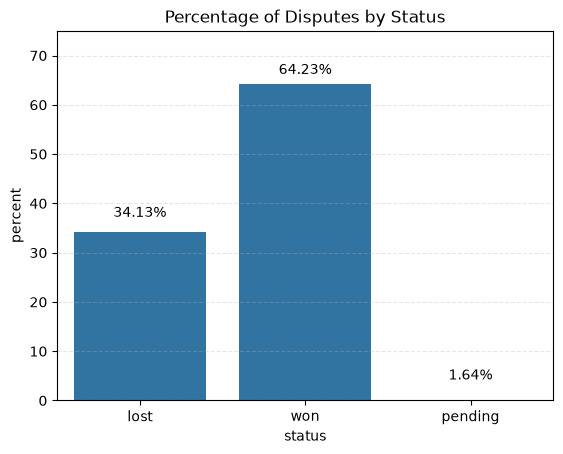

In [ ]:
status_pcns = {}
for status in ["won", "open", "lost"]:
	status_pcns[status] = fact_dispute.group_by("status").agg(
		(pl.col('dispute_id').count() / fact_dispute.shape[0] * 100).alias("percent")
	).filter(
		pl.col('status') == status
	)['percent'][0]

print(status_pcns)

sns.countplot(
    data=fact_dispute.to_pandas(),
    x="status",
	stat="percent",
	order=["lost", "won", "pending"]
)

plt.text(0, 38, f"{status_pcns['lost']:.2f}%", ha="center", va="center")
plt.text(1, 67, f"{status_pcns['won']:.2f}%", ha="center", va="center")
plt.text(2, 5, f"{status_pcns['open']:.2f}%", ha="center", va="center")

plt.title("Percentage of Disputes by Status")
plt.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.ylim(0, 75)

#### Dispute reasons

The next results count disputes by reason and visualize how reasons vary across dispute statuses.

In [ ]:
# number of disputes by reason
fact_dispute.group_by("reason").agg(
    pl.col('dispute_id').count()
)

reason,dispute_id
cat,u32
"""duplicate""",438
"""product_not_received""",448
"""unrecognized""",481
"""fraud""",467


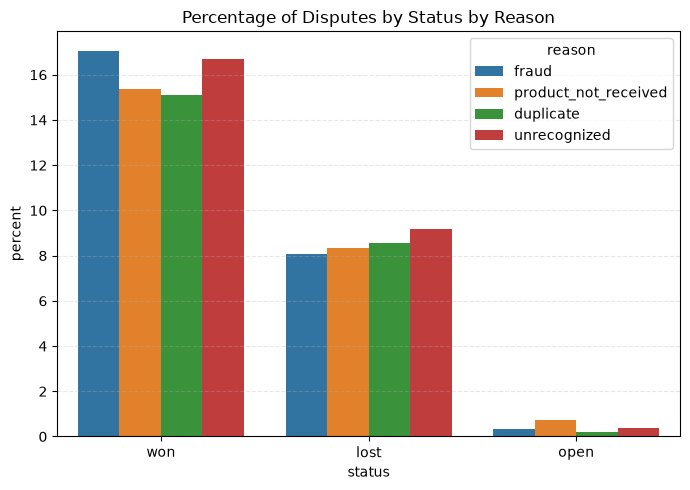

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(
	data=fact_dispute.to_pandas(),
    x="status",
    stat="percent",
	hue="reason",
)

plt.title("Percentage of Disputes by Status by Reason")
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

<a id="fact-settlement"></a>
### 3.6 `fact_settlement` — Merchant payouts

Settlement records describe payouts to merchants. The section checks data completeness, identifier uniqueness, merchant coverage, payout outcomes, failure reasons, and timing measures.

In [ ]:
fact_settlement.null_count().show()
fact_settlement.schema

settlement_id,merchant_id,currency_code,initiated_at,scheduled_at,completed_at,status,amount_minor,failure_reason,amount_major,time_to_scheduled_payout,payout_completion_time,schedule_deviation
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,4667,0,0,82168,0,0,4667,0


Schema([('settlement_id', Int64),
        ('merchant_id', Int64),
        ('currency_code', Categorical),
        ('initiated_at', Datetime(time_unit='us', time_zone=None)),
        ('scheduled_at', Datetime(time_unit='us', time_zone=None)),
        ('completed_at', Datetime(time_unit='us', time_zone=None)),
        ('status', Categorical),
        ('amount_minor', Int64),
        ('failure_reason', Categorical),
        ('amount_major', Float64),
        ('time_to_scheduled_payout', Int64),
        ('payout_completion_time', Int64),
        ('schedule_deviation', Int64)])

- Null values in the **completed_at** and **payout_completion_time** are because of the **status="failed"** or **status="pending"**.
- Null values in the **failure_reason** column is because of **status="completed"** and the settlement does not failed.

#### Settlement identifiers and merchant coverage

The next two cells examine duplicate settlement IDs and the number of distinct merchants associated with payout records.

In [ ]:
# number of non-unique settlements
fact_settlement.select('settlement_id').is_duplicated().sum()

0

In [ ]:
# number of unique merchants
fact_settlement.select('merchant_id').n_unique()

2000

#### Payout status and failure reasons

These cells summarize settlement status proportions and frequencies of recorded failure reasons.

In [ ]:
fact_settlement.group_by('status').agg(
    pl.col('settlement_id').count() / fact_settlement.shape[0] * 100
)

status,settlement_id
cat,f64
"""failed""",3.523583
"""pending""",1.956111
"""completed""",94.520307


In [ ]:
fact_settlement.group_by('failure_reason').agg(
    pl.col('settlement_id').count()
)

failure_reason,settlement_id
cat,u32
null,82168
"""bank_return""",3001


#### Payout timing statistics

The following aggregates summarize the time between payout initiation, scheduling, and completion. Some output measures are converted from seconds to hours.

**Metric definition note:** In the current `src.preprocessing` implementation, `schedule_deviation` is calculated as `scheduled_at - scheduled_at`. Its reported values therefore cannot measure actual scheduling deviation. This explanatory note does not change the underlying expression.

In [ ]:
fact_settlement.select(
    (pl.col('time_to_scheduled_payout').mean() / (60 * 60)).alias("mean_time_to_scheduled_payout"),
    (pl.col('time_to_scheduled_payout').std()).alias("std_time_to_scheduled_payout"),
    (pl.col('payout_completion_time').mean() / (3600)).alias("mean_payout_completion_time"),
    (pl.col('payout_completion_time').std() / (3600)).alias("std_payout_completion_time"),
    pl.col('schedule_deviation').mean().alias("mean_schedule_deviation"),
    pl.col('schedule_deviation').std().alias("std_schedule_deviation")
)

mean_time_to_scheduled_payout,std_time_to_scheduled_payout,mean_payout_completion_time,std_payout_completion_time,mean_schedule_deviation,std_schedule_deviation
f64,f64,f64,f64,f64,f64
24.0,0.0,28.979156,14.13535,0.0,0.0


<a id="fact-merchant-ledger"></a>
### 3.7 `fact_merchant_ledger` — Merchant ledger entries

The merchant ledger records signed balance movements by merchant and event type. This section inspects completeness, schema, unique entries, merchant coverage, and the event mix.

In [ ]:
fact_merchant_ledger.null_count().show()
fact_merchant_ledger.schema

entry_id,merchant_id,currency_code,posted_at,event_type,source_id,signed_amount_minor,signed_amount_major
u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0


Schema([('entry_id', Int64),
        ('merchant_id', Int64),
        ('currency_code', Categorical),
        ('posted_at', Datetime(time_unit='us', time_zone=None)),
        ('event_type', Categorical),
        ('source_id', Int64),
        ('signed_amount_minor', Int64),
        ('signed_amount_major', Float64)])

#### Ledger entry coverage

The next cells count distinct ledger entries and merchants. Ledger records represent account movements rather than a separate table of payment fees.

In [ ]:
# number of unique entry IDs
fact_merchant_ledger.select('entry_id').n_unique()

2995584

In [ ]:
# number of unique merchants
fact_merchant_ledger.select('merchant_id').n_unique()

2000

#### Ledger event types and example transactions

The first result counts entries by `event_type`. The following query filters ledger activity for one merchant and one date, providing a concrete record-level example.

In [ ]:
fact_merchant_ledger.group_by('event_type').agg(
    pl.col('entry_id').count()
)

event_type,entry_id
cat,u32
"""refund_debit""",42316
"""payout_debit""",80502
"""dispute_debit""",626
"""capture_credit""",1435757
"""dispute_fee_debit""",626
"""merchant_fee_debit""",1435757


In [ ]:
fact_merchant_ledger.filter(
    pl.col('posted_at').dt.date() == pl.datetime(2021, 10, 6),
    pl.col('merchant_id') == 590
)

entry_id,merchant_id,currency_code,posted_at,event_type,source_id,signed_amount_minor,signed_amount_major
i64,i64,cat,datetime[μs],cat,i64,i64,f64
1,590,"""CNY""",2021-10-06 15:50:05,"""capture_credit""",1,21107,211.07
7035,590,"""CNY""",2021-10-06 01:43:00,"""capture_credit""",7939,86256,862.56
15460,590,"""CNY""",2021-10-06 15:50:06,"""merchant_fee_debit""",1,-794,-7.94
22494,590,"""CNY""",2021-10-06 01:43:01,"""merchant_fee_debit""",7035,-2683,-26.83


<a id="saving-data"></a>
## 4. Saving processed data

The final cell contains the notebook author's existing local save function and its invocation. It is left untouched. This local function has the same name as the imported helper, and the displayed code writes only the currency table; it should not be read as a complete export of every prepared table.

In [63]:
# writing processed csv files
tables = load_data()
save_processed_data(tables)

Data loaded


In [13]:
fact_payment_intent.join(
	other=dim_merchant,
    on="merchant_id",
    how="left"
).join(
    other=dim_customer,
	on="customer_id",
	how="left"
).select(
    cs.by_name(
        'intent_id', 'merchant_id', 'customer_id',
        'buyer_country'
	),
    cs.by_name('country_code').alias("merchant_country"),
    cs.by_name('country_code_right').alias("customer_country")
).filter(
    pl.col('buyer_country') != pl.col('merchant_country')
)

intent_id,merchant_id,customer_id,buyer_country,merchant_country,customer_country
i64,i64,i64,cat,cat,cat
220,232,14195,"""AU""","""GB""","""US"""
222,1040,34,"""US""","""GB""","""GB"""
396,858,15974,"""AU""","""US""","""GB"""
499,1898,8847,"""CA""","""US""","""US"""
514,1287,null,"""RU""","""GB""",null
…,…,…,…,…,…
1612254,1227,141,"""FR""","""GB""","""CN"""
1612291,1309,71936,"""GB""","""EG""","""GB"""
1612337,83,38879,"""JP""","""EG""","""GB"""


In [14]:
dim_gateway

gateway_id,gateway_name,home_region,is_enabled
i64,str,str,i64
1,"""AtlasFlow""","""North America""",1
2,"""BlueHarbor""","""Europe""",1
3,"""OrbitRoute""","""APAC""",1
4,"""NovaSwitch""","""Global""",1
5,"""PineBridge""","""Emerging Markets""",1
